# How the scheme works: deforming the Fresnel integral into the complex plane

This notebook is about the **method**, not the results: what the solver actually integrates
along, and why that is possible.  Everything shown is computed live from the repository's own
engines and its method-independent reference layer (`comparison/referee.py`).

* **Section 1** — the base case: a quadratic phase.  On the real axis the integrand oscillates
  and converges only conditionally; rotated by $\pi/4$ it becomes a Gaussian.  This is the
  entire trick in one picture.
* **Section 2** — a rational lens: the *actual* Lefschetz thimbles the 1D solver traces
  (`RationalLens.thimble`), drawn on the height $\mathrm{Re}(i\omega\varphi)$, together with
  the naive alternative (truncated real-axis quadrature with exact Fresnel tails bolted on).
* **Section 3** — the 2D field.  A point-mass field's Fresnel integral is 2 complex = 4 real
  dimensions, and a thimble is a 2-real-dimensional surface inside it — not directly
  drawable.  But the solver's construction is *recursive*, and each level is one complex
  plane: we can look at the outer contour with the real outer integrand on it, and at the
  inner plane slice by slice, exactly as the algorithm visits it.

The honest caveat, up front: Section 3 shows **one-dimensional slices of the algorithm's
contour**, not a picture of the 4-dimensional thimble.  What makes it convincing rather than
just illustrative is that the quantities plotted are the real ones (the phase, the inner
integral, the branch-point positions) and that the arithmetic checks out at the end
(Section 3.4: contour independence at $10^{-16}$).


In [1]:
import os, sys, math, warnings
root = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(root, 'pyproject.toml')) and root != '/':
    root = os.path.dirname(root)
sys.path.insert(0, root); os.chdir(root)

import numpy as np
import matplotlib.pyplot as plt
import fastpiclef as fpl
from comparison import referee as R          # the method-independent reference layer
from scipy.integrate import IntegrationWarning
warnings.filterwarnings('ignore', category=IntegrationWarning)   # sec. 2's naive-quadrature chatter

E4 = np.exp(1j * np.pi / 4)
print('fastpiclef ready; referee functions:', [f for f in dir(R) if not f.startswith('__')][:8], '...')


fastpiclef ready; referee functions: ['TWO_MASS_BETA', 'TWO_MASS_LENSES', '_E4', '_GL_RULE_MP_CACHE', '_W20', '_X20', '_adapt', '_adapt_mp'] ...


## 1. The base case: one quadratic phase, two contours

Take the free-space integral $I = \int_{\mathbb{R}} e^{i\omega z^2/2}\,dz$ with $\omega = 3$.
On the real axis the integrand oscillates forever ($|e^{i\omega x^2/2}| = 1$ for every $x$) and
the integral converges only conditionally: truncating at $\pm X$ leaves an error
$\sim 1/(\omega X)$.  Rotate the contour by $\pi/4$: with $z = e^{i\pi/4}s$,

$$e^{i\omega z^2/2} = e^{-\omega s^2/2}\quad\text{(a Gaussian!)}, \qquad dz = e^{i\pi/4} ds,$$

and the quadrature becomes trivial.  The exact value is
$\sqrt{2\pi i/\omega} = \sqrt{2\pi/\omega}\,e^{i\pi/4}$.


In [2]:
w = 3.0
exact = np.sqrt(2j * np.pi / w)

print(f"{'X':>6} {'Re I(X)':>14} {'Im I(X)':>14} {'rel err vs exact':>18}   <- naive real-axis truncation")
for X in [4.0, 8.0, 16.0, 32.0, 64.0]:
    xs = np.linspace(-X, X, int(2e5 * X / 64) * 8 + 1)
    I = np.trapezoid(np.exp(0.5j * w * xs * xs), xs)
    print(f"{X:6.0f} {I.real:14.9f} {I.imag:14.9f} {abs(I - exact)/abs(exact):18.2e}")

s = np.linspace(-14.0, 14.0, 40001)                 # the full rotated line
I_rot = np.trapezoid(np.exp(-0.5 * w * s * s) * E4, s)
print(f"\nrotated line (full): |I - exact| / |exact| = {abs(I_rot - exact)/abs(exact):.2e}  (Gaussian quadrature)")
print(f"exact         : sqrt(2*pi*i/w)      = {exact:.12f}")


     X        Re I(X)        Im I(X)   rel err vs exact   <- naive real-axis truncation
     4    0.871127147    0.955845349           1.15e-01
     8    1.105363944    1.037934621           5.76e-02
    16    1.050938302    0.992122670           2.88e-02


    32    1.028261276    1.043567096           1.44e-02


    64    1.014821732    1.017312720           7.20e-03

rotated line (full): |I - exact| / |exact| = 0.00e+00  (Gaussian quadrature)
exact         : sqrt(2*pi*i/w)      = 1.023326707946+1.023326707946j


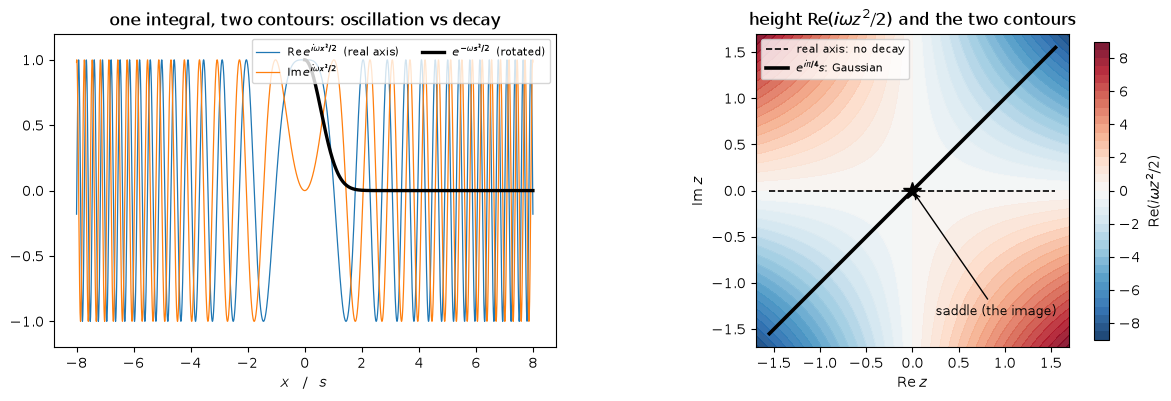

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11.6, 3.9), constrained_layout=True)

# left: the same integrand on the two contours
xl = np.linspace(-8, 8, 4001)
f_real = np.exp(0.5j * w * xl * xl)
sl = np.linspace(0, 8, 2001)
ax[0].plot(xl, f_real.real, lw=0.9, label=r'$\mathrm{Re}\,e^{i\omega x^2/2}$  (real axis)')
ax[0].plot(xl, f_real.imag, lw=0.9, label=r'$\mathrm{Im}\,e^{i\omega x^2/2}$')
ax[0].plot(sl, np.exp(-0.5 * w * sl * sl), 'k', lw=2.4, label=r'$e^{-\omega s^2/2}$  (rotated)')
ax[0].set(xlabel='$x$   /   $s$', ylim=(-1.2, 1.2),
          title='one integral, two contours: oscillation vs decay')
ax[0].legend(fontsize=8, ncol=2, loc='upper right')

# right: the landscape and the deformation, in the complex plane
g = np.linspace(-1.7, 1.7, 321)
GX, GY = np.meshgrid(g, g)
W = np.real(1j * w * (GX + 1j * GY) ** 2 / 2)
cf = ax[1].contourf(GX, GY, W, levels=41, cmap='RdBu_r', alpha=0.9)
plt.colorbar(cf, ax=ax[1], shrink=0.95, label=r'$\mathrm{Re}(i\omega z^2/2)$')
ax[1].plot([-1.55, 1.55], [0, 0], 'k--', lw=1.2, label='real axis: no decay')
ax[1].plot([-1.55, 1.55], [-1.55, 1.55], 'k', lw=2.6, label=r'$e^{i\pi/4}s$: Gaussian')
ax[1].plot(0, 0, 'k*', ms=13)
ax[1].annotate('saddle (the image)', xy=(0, 0), xytext=(0.25, -1.35),
               arrowprops=dict(arrowstyle='->', lw=1), fontsize=9)
ax[1].set(xlabel='Re $z$', ylabel='Im $z$', aspect='equal',
          title=r'height $\mathrm{Re}(i\omega z^2/2)$ and the two contours')
ax[1].legend(fontsize=8, loc='upper left')
plt.show()


## 2. A rational lens: the thimbles the code actually traces

The 1D test lens of the repository, $\varphi(z) = \tfrac12(z-\beta)^2 - \kappa/(1+z^2)$ with
$\beta = 0.2$, $\kappa = -1.2$, is analytic in the whole plane minus two poles at $z = \pm i$.
Above we saw the free-space rotation; here the real *lens* adds topology: several saddles, and
the integration contour must be deformed onto the steepest-descent pieces attached to them —
the **Lefschetz thimbles**.

The Python API exposes exactly what the solver uses: `RationalLens.saddles()` (the complete
stationary set, from the polynomial saddle source) and `RationalLens.thimble(omega)` (the
traced pieces).  We draw them on the height landscape $\mathrm{Re}(i\omega\varphi)$.


saddles: [-0.5794-0.j     -0.1552+0.j      0.0303-1.5946j  0.0303+1.5946j
  0.8741+0.j    ]
thimble pieces: [110, 113, 110] points each


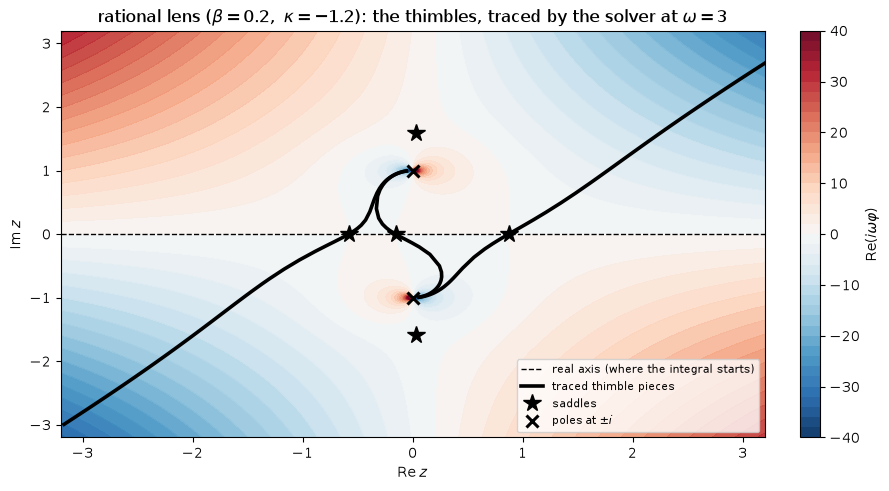

In [4]:
lens = fpl.RationalLens(beta=0.2, kappa=-1.2)
w1 = 3.0
saddles = np.array(lens.saddles())
pieces = [np.asarray(p) for p in lens.thimble(omega=w1)]
print('saddles:', np.round(saddles, 4))
print('thimble pieces:', [len(p) for p in pieces], 'points each')

def phi1(z):            # the model phase, complex-analytic
    return 0.5 * (z - 0.2) ** 2 + 1.2 / (1.0 + z * z)

g = np.linspace(-3.2, 3.2, 480)          # even count: keeps the grid off the poles at +/- i
GX, GY = np.meshgrid(g, g)
with np.errstate(divide='ignore', invalid='ignore'):
    W = np.real(1j * w1 * phi1(GX + 1j * GY))
W = np.clip(W, -40, 40)

fig, ax = plt.subplots(figsize=(8.8, 4.8), constrained_layout=True)
cf = ax.contourf(GX, GY, W, levels=41, cmap='RdBu_r', alpha=0.95)
plt.colorbar(cf, ax=ax, label=r'$\mathrm{Re}(i\omega\varphi)$')
ax.plot([-3.2, 3.2], [0, 0], 'k--', lw=1, label='real axis (where the integral starts)')
for p in pieces:
    ax.plot(p.real, p.imag, color='k', lw=2.6)
ax.plot([], [], color='k', lw=2.6, label='traced thimble pieces')
ax.plot(saddles.real, saddles.imag, 'k*', ms=13, label='saddles')
ax.plot([0, 0], [1, -1], 'kx', ms=9, mew=2.2, label=r'poles at $\pm i$')
ax.set(xlabel='Re $z$', ylabel='Im $z$', xlim=(-3.2, 3.2), ylim=(-3.2, 3.2),
       title=r'rational lens ($\beta=0.2,\ \kappa=-1.2$): the thimbles, traced by the solver at $\omega=3$')
ax.legend(fontsize=8, loc='lower right')
plt.show()


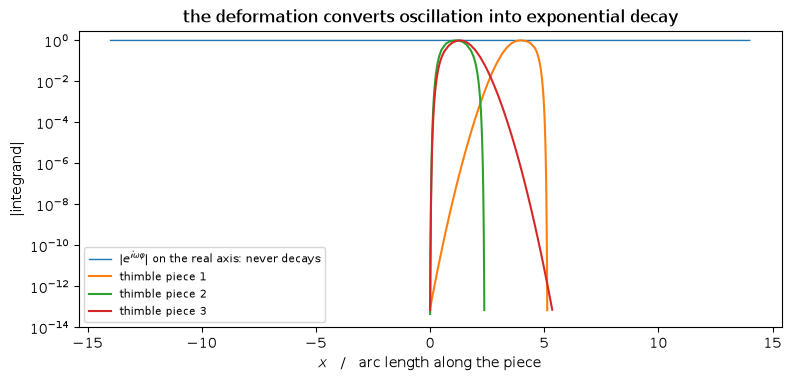

thimble (deformed contour)  : -2.072097104761-1.063859589825j   (budget 3.8e-09)
mesh flow (independent code): -2.072097104761-1.063859589825j   (budget 2.7e-15)
rel diff = 3.1e-15

     L    naive real axis + exact Fresnel tails   rel dev vs thimble
    10    -2.0703851790   -1.0653694225j              9.8e-04
    20    -2.0723495909   -1.0638656895j              1.1e-04
    40    -2.0720812951   -1.0638612658j              6.8e-06


    80    -2.0720994932   -1.0638577741j              1.3e-06


   160    -2.0720970066   -1.0638595506j              4.5e-08

the residual decays only algebraically: the potential tail is not exactly quadratic,
so even with exact free-space Fresnel tails bolted on, the real-axis route stalls
around 1e-8 -- while the deformed contour is at machine precision.


In [5]:
fig, ax = plt.subplots(figsize=(7.8, 3.7), constrained_layout=True)
xx = np.linspace(-14, 14, 4001)
ax.semilogy(xx, np.abs(np.exp(1j * w1 * phi1(xx))), lw=1.0,
            label=r'$|e^{i\omega\varphi}|$ on the real axis: never decays')
for k, p in enumerate(pieces):
    t = np.concatenate([[0.0], np.cumsum(np.abs(np.diff(p)))])
    ax.semilogy(t, np.abs(np.exp(1j * w1 * phi1(p))), lw=1.5, label=f'thimble piece {k+1}')
ax.set(xlabel='$x$   /   arc length along the piece', ylabel='|integrand|', ylim=(1e-14, 3),
       title='the deformation converts oscillation into exponential decay')
ax.legend(fontsize=8)
plt.show()

th = lens.solve(omega=w1, method='thimble')
me = lens.solve(omega=w1, method='mesh', delta=0.01, domain=(-30, 30))
print(f'thimble (deformed contour)  : {th.integral:.12f}   (budget {th.error:.1e})')
print(f'mesh flow (independent code): {me.integral:.12f}   (budget {me.error:.1e})')
print(f'rel diff = {abs(th.integral - me.integral)/abs(th.integral):.1e}')
print()
print(f"{'L':>6} {'naive real axis + exact Fresnel tails':>40} {'rel dev vs thimble':>20}")
for L in [10.0, 20.0, 40.0, 80.0, 160.0]:
    ref = R.lens_referee(phi1, beta=0.2, omega=w1, L=L)
    print(f'{L:6.0f} {ref.real:16.10f}{ref.imag:+16.10f}j {abs(ref - th.integral)/abs(th.integral):20.1e}')
print()
print('the residual decays only algebraically: the potential tail is not exactly quadratic,')
print('so even with exact free-space Fresnel tails bolted on, the real-axis route stalls')
print('around 1e-8 -- while the deformed contour is at machine precision.')


## 3. The 2D field: slicing the 4-dimensional construction

The lensing integral is truly two-dimensional: $I = \int_{\mathbb{R}^2} e^{i\omega\varphi(x_0,x_2)}\,dx_0\,dx_2$.
Complexifying both variables gives a 4-real-dimensional space; the contour the solver
integrates along is a 2-real-dimensional surface in it (the "thimble" of the full problem).
We cannot draw that surface — but we do not have to: the solver's construction is
**recursive**.  The outer variable has its own real core + rotated tails; for every point on
it, the inner integral runs along *its* own core + tails in the inner plane, with the inner
branch points shifted by the outer point.  Each level is a plane picture; the algorithm is the
family of those pictures.

### 3.1 The outer contour, with the real inner integral on it

We use the repository's canonical two-mass field
$\psi = \sum_j m_j \ln|x-a_j|$ with $a_1 = (-0.8, 0.5)$, $m_1 = 0.6$ and
$a_2 = (0.9, -0.4)$, $m_2 = 0.4$, source $\boldsymbol\beta = (0.2, 0.1)$, and compute the
**real** inner integral $G(x_2) = \int dz_0\,e^{i\omega\varphi(z_0,x_2)}$ with the reference
layer (`slice_referee`, itself an independent RC implementation) at real and complex $x_2$.


In [6]:
lenses = R.TWO_MASS_LENSES
beta2 = R.TWO_MASS_BETA
w2 = 3.0
margin = 1.5
bs = [b for _, b, _ in lenses]
A2 = min([beta2[1]] + bs) - margin     # outer core: covers every pinch height b_j and beta_2
B2 = max([beta2[1]] + bs) + margin
print('lenses (x, y, m):', lenses)
print('beta:', beta2)
print(f'outer core: x2 in [{A2:.2f}, {B2:.2f}]  (pinch heights at {bs})')

# sample G(x2) along the solver's outer contour: real core + two pi/4 tails
core = np.linspace(A2, B2, 161)
t_s = np.linspace(0.0, 3.0, 41)
right = B2 + E4 * t_s
left = A2 - E4 * t_s
G_core = np.array([R.slice_referee(z, w2, lenses, beta2, margin=1.5) for z in core])
G_right = np.array([R.slice_referee(z, w2, lenses, beta2, margin=1.5) for z in right])
G_left = np.array([R.slice_referee(z, w2, lenses, beta2, margin=1.5) for z in left])
print('sampled', len(core) + 2 * len(t_s), 'points of the outer integrand G(x2)')


lenses (x, y, m): [(-0.8, 0.5, 0.6), (0.9, -0.4, 0.4)]
beta: (0.2, 0.1)
outer core: x2 in [-1.90, 2.00]  (pinch heights at [0.5, -0.4])


sampled 243 points of the outer integrand G(x2)


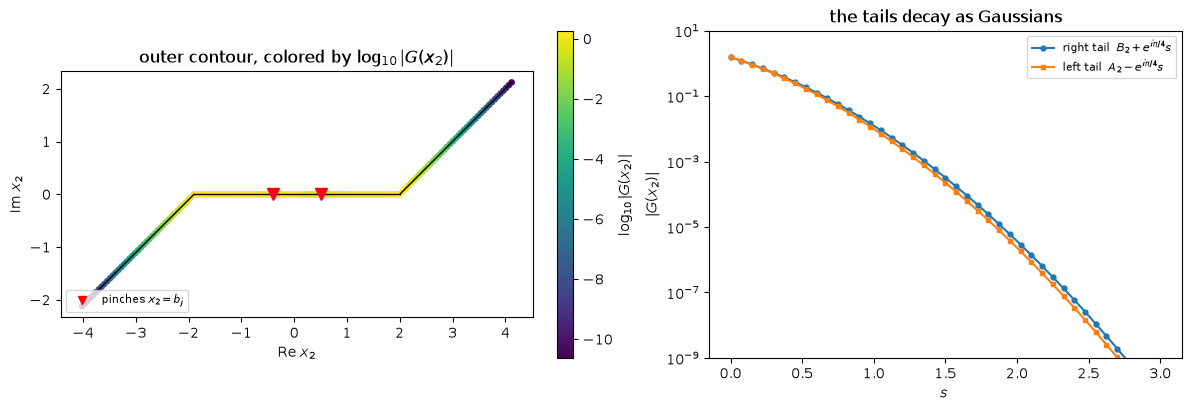

fit of ln|G| vs s : s^2 coefficient -1.567   (predicted -omega/2 = -1.500)
                    s   coefficient -3.442   (predicted -omega*B2/sqrt2 = -4.243;
                    the point-mass log terms add a slowly-varying contribution)


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11.8, 4.0), constrained_layout=True)

sc = ax[0].scatter(np.r_[core, right, left].real, np.r_[core, right, left].imag,
                   c=np.log10(np.abs(np.r_[G_core, G_right, G_left])), s=14, cmap='viridis')
ax[0].plot(core, 0 * core, 'k-', lw=1)
ax[0].plot(right.real, right.imag, 'k-', lw=1)
ax[0].plot(left.real, left.imag, 'k-', lw=1)
for _, b, _ in lenses:
    ax[0].plot(b, 0, 'rv', ms=8)
ax[0].plot([], [], 'rv', label='pinches $x_2 = b_j$')
ax[0].set(xlabel='Re $x_2$', ylabel='Im $x_2$', aspect='equal',
          title='outer contour, colored by $\\log_{10}|G(x_2)|$')
ax[0].legend(fontsize=8, loc='lower left')
plt.colorbar(sc, ax=ax[0], label=r'$\log_{10}|G(x_2)|$')

ax[1].semilogy(t_s, np.abs(G_right), 'o-', ms=3.5, label='right tail  $B_2 + e^{i\\pi/4}s$')
ax[1].semilogy(t_s, np.abs(G_left), 's-', ms=3.5, label='left tail  $A_2 - e^{i\\pi/4}s$')
ax[1].set(xlabel='$s$', ylabel='$|G(x_2)|$', ylim=(1e-9, 10),
          title='the tails decay as Gaussians')
ax[1].legend(fontsize=8)
plt.show()

# the decay is the product of the quadratic factor and the linear phase factor:
#   ln|G|  ~  const - (omega*B2/sqrt(2)) s - (omega/2) s^2      (+ slowly-varying log terms)
m = t_s >= 1.5                      # the large-s window where the s^2 term dominates
c2, c1, _ = np.polyfit(t_s[m], np.log(np.abs(G_right))[m], 2)
print(f'fit of ln|G| vs s : s^2 coefficient {c2:.3f}   (predicted -omega/2 = {-0.5*w2:.3f})')
print(f'                    s   coefficient {c1:.3f}   (predicted -omega*B2/sqrt2 = {-w2*B2/np.sqrt(2):.3f};')
print(f'                    the point-mass log terms add a slowly-varying contribution)')


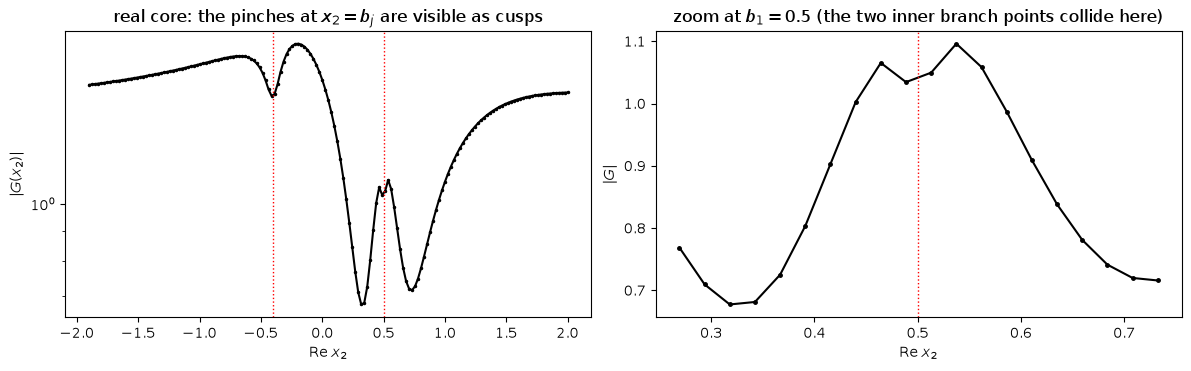

|G| at the pinch b_1: 1.0344e+00   |G| one panel away: 7.1984e-01
a quadrature that straddled a pinch would see this singular behaviour; the solver anchors
its panels AT the pinches (x2 = b_j +/- rho^2) so no panel ever spans one.


In [8]:
# Cusps at the pinches: |G| along the real core, zoomed at each b_j
fig, ax = plt.subplots(1, 2, figsize=(11.8, 3.6), constrained_layout=True)
ax[0].plot(core, np.abs(G_core), 'k.-', ms=3)
for _, b, _ in lenses:
    ax[0].axvline(b, color='r', ls=':', lw=1)
ax[0].set(xlabel='Re $x_2$', ylabel='$|G(x_2)|$', yscale='log',
          title='real core: the pinches at $x_2 = b_j$ are visible as cusps')
z0 = lenses[0][1]
m0 = np.abs(core - z0) < 0.25
ax[1].plot(core[m0], np.abs(G_core)[m0], 'k.-', ms=5)
ax[1].axvline(z0, color='r', ls=':', lw=1)
ax[1].set(xlabel='Re $x_2$', ylabel='$|G|$', title=f'zoom at $b_1 = {z0}$ (the two inner branch points collide here)')
plt.show()

proof = np.abs(G_core[np.argmin(np.abs(core - lenses[0][1]))])
print(f'|G| at the pinch b_1: {proof:.4e}   |G| one panel away: '
      f'{np.abs(G_core[np.argmin(np.abs(core - (lenses[0][1] + 0.2)))]):.4e}')
print('a quadrature that straddled a pinch would see this singular behaviour; the solver anchors')
print('its panels AT the pinches (x2 = b_j +/- rho^2) so no panel ever spans one.')


### 3.2 The inner plane, slice by slice

Fix a point $x_2$ on the outer contour.  The inner integrand,
$e^{i\omega\varphi(z_0,\,x_2)}$, has branch points where $w_j = (z_0-a_j)^2+(x_2-b_j)^2 = 0$:

$$p_j = a_j + i\,(x_2-b_j), \qquad q_j = a_j - i\,(x_2-b_j).$$

For real $x_2$ the two families sit on the imaginary axis through each $a_j$; as the outer
point moves onto a tail ($x_2$ complex), they separate **horizontally** by
$\mp\,\mathrm{Im}(x_2-b_j)$ — and that is exactly why the inner core widens by
$|\mathrm{Im}\,x_2|$: both families must stay *inside* the core at all times.


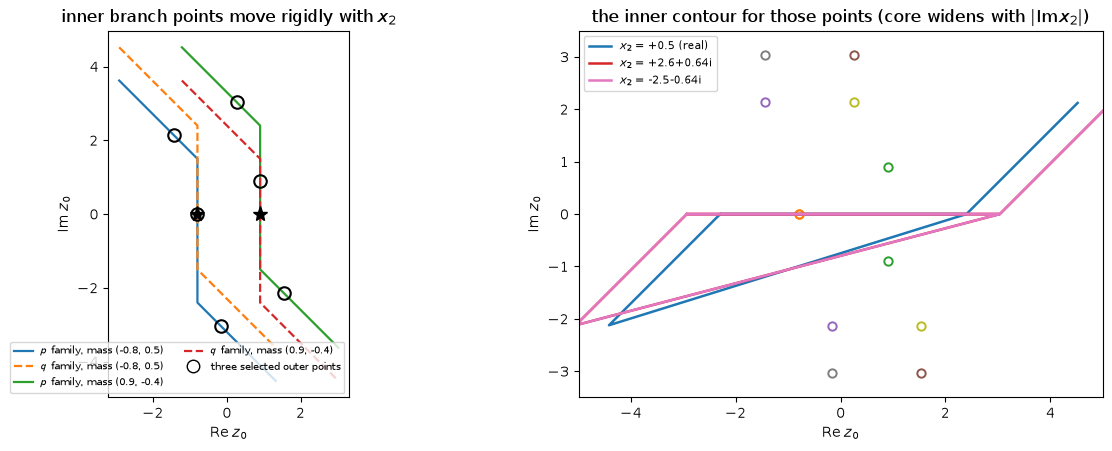

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11.8, 4.4), constrained_layout=True)

# left: trajectories of the inner branch points as x2 runs along the outer contour
allpts = np.r_[left[::-1], core, right]
for (a, b, m) in lenses:
    p = a + 1j * (allpts - b)
    q = a - 1j * (allpts - b)
    ax[0].plot(p.real, p.imag, '-', lw=1.6, label=f'$p$ family, mass ({a}, {b})')
    ax[0].plot(q.real, q.imag, '--', lw=1.6, label=f'$q$ family, mass ({a}, {b})')
    ax[0].plot(a, 0, 'k*', ms=11)
sel = [0.5 + 0j, B2 + E4 * 0.9, A2 - E4 * 0.9]
for x2 in sel:
    xs = [a + 1j * (x2 - b) for a, b, _ in lenses]
    ax[0].plot([z.real for z in xs], [z.imag for z in xs], 'ko', mfc='none', ms=9, mew=1.5)
ax[0].plot([], [], 'ko', mfc='none', ms=9, label='three selected outer points')
ax[0].set(xlabel='Re $z_0$', ylabel='Im $z_0$', aspect='equal',
          title='inner branch points move rigidly with $x_2$')
ax[0].legend(fontsize=7, loc='lower right', ncol=2)

# right: the inner contour for the three selected outer points
aov = [a for a, _, _ in lenses]
for x2 in sel:
    sh = abs(np.imag(x2))
    A0 = min([beta2[0]] + aov) - 1.5 - sh
    B0 = max([beta2[0]] + aov) + 1.5 + sh
    tt = np.linspace(0, 3.0, 60)
    path = np.r_[B0 + E4 * tt[::-1], np.linspace(A0, B0, 120), A0 - E4 * tt[::-1]]
    lbl = f'$x_2$ = {x2.real:+.1f}{x2.imag:+.2f}i' if abs(np.imag(x2)) > 1e-9 else f'$x_2$ = {x2.real:+.1f} (real)'
    ax[1].plot(path.real, path.imag, lw=1.8, label=lbl)
    for (a, b, _) in lenses:
        p = a + 1j * (x2 - b)
        q = a - 1j * (x2 - b)
        ax[1].plot([p.real, q.real], [p.imag, q.imag], 'o', ms=6, mfc='none', mew=1.4)
ax[1].set(xlabel='Re $z_0$', ylabel='Im $z_0$', aspect='equal', xlim=(-5, 5), ylim=(-3.5, 3.5),
          title='the inner contour for those points (core widens with $|\\mathrm{Im}\\,x_2|$)')
ax[1].legend(fontsize=8, loc='upper left')
plt.show()


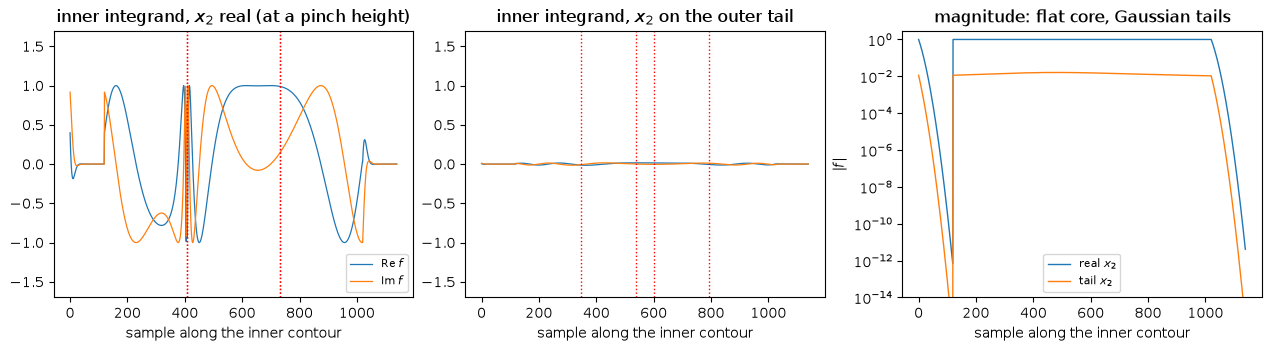

the inner core is genuinely oscillatory (|f| = 1 on the real axis, phase winding); the
rotated tails decay like a Gaussian.  The red lines mark the branch points: strictly
inside the core, by the construction that anchors and widens it.


In [10]:
# The inner integrand along the inner contour: oscillatory core, exponentially decaying tails.
def inner_path(x2, margin=1.5, nt=900, tl=3.0):
    sh = abs(np.imag(x2))
    A0 = min([beta2[0]] + aov) - margin - sh
    B0 = max([beta2[0]] + aov) + margin + sh
    tt = np.linspace(0, tl, 120)
    return np.r_[A0 - E4 * tt, np.linspace(A0, B0, nt), B0 + E4 * tt]

cases = [(0.5 + 0j, 'real (at a pinch height)'), (B2 + E4 * 0.9, 'on the outer tail')]
fig, ax = plt.subplots(1, 3, figsize=(12.6, 3.4), constrained_layout=True)
for j, (x2, lab) in enumerate(cases):
    path = inner_path(x2)
    f = np.exp(1j * w2 * R._phi_c(path, x2, beta2, lenses))
    ax[j].plot(f.real, lw=0.9, label=r'Re $f$')
    ax[j].plot(f.imag, lw=0.9, label=r'Im $f$')
    ax[j].set(xlabel='sample along the inner contour', ylim=(-1.7, 1.7),
              title=f'inner integrand, $x_2$ {lab}')
    for (a, b, _) in lenses:
        for z in [a + 1j * (x2 - b), a - 1j * (x2 - b)]:
            k = np.argmin(np.abs(path - z))
            ax[j].axvline(k, color='r', ls=':', lw=1.0)
ax[0].legend(fontsize=8, loc='lower right')
ax[0].plot([], [], 'r:', label='branch points')
for x2, lab in cases:
    path = inner_path(x2)
    f = np.exp(1j * w2 * R._phi_c(path, x2, beta2, lenses))
    ax[2].semilogy(np.abs(f), lw=1.0, label=('real $x_2$' if x2.imag == 0 else 'tail $x_2$'))
ax[2].set(xlabel='sample along the inner contour', ylabel='$|f|$', ylim=(1e-14, 3),
          title='magnitude: flat core, Gaussian tails')
ax[2].legend(fontsize=8)
plt.show()
print('the inner core is genuinely oscillatory (|f| = 1 on the real axis, phase winding); the')
print('rotated tails decay like a Gaussian.  The red lines mark the branch points: strictly')
print('inside the core, by the construction that anchors and widens it.')


### 3.3 Does it add up?  Contour independence, quantitatively

If the deformation is exact (Cauchy), then the value must not depend on the contour's free
parameters: the core extents (margins) and the tail length.  The solver exposes its margins
(`solve(omega, margin=..., margin_outer=...)`), and the reference layer can be run with two
different inner margins — the repository's standard self-check.  And the crude question —
"why not just integrate along the real axis?" — answers itself in the last line.


In [11]:
field2 = fpl.PointMassField(lenses, beta=beta2)
base = field2.solve(omega=w2)
print(f'exact solver (adaptive, budget {base.error:.1e}): {base.integral:.12f}')
print()
print(f"{'margin':>8} {'margin_outer':>13} {'rel deviation from the default contour':>40}")
for m, mo in [(1.0, 1.5), (1.5, 1.0), (2.0, 1.5), (3.0, 2.5), (1.5, 2.5)]:
    r = field2.solve(omega=w2, margin=m, margin_outer=mo)
    print(f'{m:8.1f} {mo:13.1f} {abs(r.integral - base.integral)/abs(base.integral):40.2e}')
g1 = R.slice_referee(right[10], w2, lenses, beta2, margin=1.0)
g2 = R.slice_referee(right[10], w2, lenses, beta2, margin=3.0)
print(f'\ntwo-contour check of G(x2) at a complex x2 = {right[10]:.3f} (inner margins 1.0 vs 3.0):')
print(f'  rel diff = {abs(g1 - g2)/abs(g1):.2e}   (independent RC implementation)')


exact solver (adaptive, budget 1.5e-13): -0.437797336629+2.968066928421j

  margin  margin_outer   rel deviation from the default contour


     1.0           1.5                                 4.54e-16
     1.5           1.0                                 2.37e-16
     2.0           1.5                                 3.89e-16
     3.0           2.5                                 9.62e-16
     1.5           2.5                                 5.65e-16

two-contour check of G(x2) at a complex x2 = 2.530+0.530j (inner margins 1.0 vs 3.0):
  rel diff = 1.98e-15   (independent RC implementation)


In [12]:
# A "dumb" quadrature along the solver's contour: the deformation does the work, not the quadrature.
fine_core = np.linspace(A2, B2, 4801)
Gf = np.array([R.slice_referee(z, w2, lenses, beta2, margin=1.5) for z in fine_core])
core_only = np.trapezoid(Gf, fine_core)                     # real axis, truncated at the core
sf = np.linspace(0.0, 7.0, 701)
Gr = np.array([R.slice_referee(B2 + E4 * q, w2, lenses, beta2, margin=1.5) for q in sf])
Gl = np.array([R.slice_referee(A2 - E4 * q, w2, lenses, beta2, margin=1.5) for q in sf])
t_right = np.trapezoid(Gr * E4, sf)
# the contour is a single traversal: [far-left] -> core -> [far-right], so BOTH tails
# carry the same measure factor e^{i pi/4}; pointing the left tail "outward" is the
# mirror-image contour and gives a different (wrong) answer:
t_left_ok = np.trapezoid(Gl * E4, sf)        # far -> near (the solver's traversal)
t_left_no = np.trapezoid(Gl * (-E4), sf)     # near -> far (mirror image)
print(f'real-axis core only, trapezoid       : {core_only:.6f}   rel dev {abs(core_only-base.integral)/abs(base.integral):.1e}')
print(f'core + tails, wrong left orientation : {core_only+t_right+t_left_no:.6f}   rel dev {abs(core_only+t_right+t_left_no-base.integral)/abs(base.integral):.1e}')
print(f'core + tails, solver orientation     : {core_only+t_right+t_left_ok:.6f}   rel dev {abs(core_only+t_right+t_left_ok-base.integral)/abs(base.integral):.1e}')
print(f'adaptive exact engine                : {base.integral:.6f}   budget {base.error:.1e}')
print()
print('The real-axis evaluation converges only conditionally; the deformed contour fixes')
print('that, but it must be traversed as a single path (left tail ENTERING the core), which')
print('is exactly what the solver does.  With the orientation right, even a crude uniform')
print('trapezoid lands at 1e-5; the adaptive engine takes it to its 1e-13 budget.')


real-axis core only, trapezoid       : -0.957665+3.338258j   rel dev 2.1e-01
core + tails, wrong left orientation : -1.031523+3.216275j   rel dev 2.1e-01
core + tails, solver orientation     : -0.437848+2.967963j   rel dev 3.9e-05
adaptive exact engine                : -0.437797+2.968067j   budget 1.5e-13

The real-axis evaluation converges only conditionally; the deformed contour fixes
that, but it must be traversed as a single path (left tail ENTERING the core), which
is exactly what the solver does.  With the orientation right, even a crude uniform
trapezoid lands at 1e-5; the adaptive engine takes it to its 1e-13 budget.


## What this notebook shows, in one paragraph

The solver does not fight oscillatory integrands: it moves the integration path (exactly, by
Cauchy) to where the integrand decays — the $\pi/4$ rotation of the quadratic phase, the
traced thimbles of a rational lens, and, in two dimensions, a real core anchored at every
branch-point pinch with rotated Gaussian tails, applied recursively (outer and inner
variable).  The pictures above are made of the solver's own objects (`thimble`, `saddles`,
`margin`) and of a method-independent reference layer computing the *same* integrals on
*different* contours; their agreement at $10^{-15}$-class is the evidence that the
construction is exact — not an approximation of the right answer, but the same number
computed another way.

**Where to look next:** `getting_started.ipynb` (the API and fast paths),
`comparison.ipynb` (accuracy and speed against `plind`, `P-LPI`, FIONA), and
`docs/error_budget.md` (every error term and its dataset).
